In [1]:
!pip install pandas numpy scipy scikit-learn pyarrow matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import os
import zipfile
import requests

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

from datetime import datetime, timezone

In [3]:
for folder in ['bronze', 'silver', 'gold']:
    os.makedirs(folder, exist_ok=True)

print("Bronze, Silver and Gold folders created!")

Bronze, Silver and Gold folders created!


In [4]:
url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

response = requests.get(url)

with open("book-crossings.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("book-crossings.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [5]:
users = pd.read_csv(
    "dataset/BX-Users.csv",
    sep=";",
    encoding="latin-1"
)

books = pd.read_csv(
    "dataset/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn"
)

ratings = pd.read_csv(
    "dataset/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1"
)

print("All three datasets loaded!")

/tmp/ipykernel_46562/2849526728.py:7: ParserWarning: Skipping line 6452: expected 8 fields, saw 9
Skipping line 43667: expected 8 fields, saw 10
Skipping line 51751: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_46562/2849526728.py:7: ParserWarning: Skipping line 92038: expected 8 fields, saw 9
Skipping line 104319: expected 8 fields, saw 9
Skipping line 121768: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_46562/2849526728.py:7: ParserWarning: Skipping line 144058: expected 8 fields, saw 9
Skipping line 150789: expected 8 fields, saw 9
Skipping line 157128: expected 8 fields, saw 9
Skipping line 180189: expected 8 fields, saw 9
Skipping line 185738: expected 8 fields, saw 9

  books = pd.read_csv(
/tmp/ipykernel_46562/2849526728.py:7: ParserWarning: Skipping line 209388: expected 8 fields, saw 9
Skipping line 220626: expected 8 fields, saw 9
Skipping line 227933: expected 8 fields, saw 11
Skipping line 228957: expected 8 fields, saw 10
Skipping line

All three datasets loaded!


In [6]:
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Users: (278858, 3)
Books: (271360, 8)
Ratings: (1149780, 3)


In [7]:
# Converting mixed-type column to string for Parquet compatibility
books["Year-Of-Publication"] = (
    books["Year-Of-Publication"].astype("string")
)

# Adding ingestion timestamp
timestamp = datetime.now(timezone.utc)

users["ingestion_timestamp"] = timestamp
books["ingestion_timestamp"] = timestamp
ratings["ingestion_timestamp"] = timestamp

# Saving as Parquet
users.to_parquet("bronze/users.parquet", index=False)
books.to_parquet("bronze/books.parquet", index=False)
ratings.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze layer created successfully!")

Bronze layer created successfully!


In [8]:
print(users.shape)
print(books.shape)
print(ratings.shape)

print("\nBronze files:")
print(os.listdir("bronze"))

(278858, 4)
(271360, 9)
(1149780, 4)

Bronze files:
['books.parquet', 'ratings.parquet', 'users.parquet']


## Exploratory Data Analysis (EDA)

In [9]:
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

print("Bronze data loaded successfully!")

Bronze data loaded successfully!


In [10]:
datasets = {
    "Users": users,
    "Books": books,
    "Ratings": ratings
}

for name, df in datasets.items():

    print("\n==========", name, "==========")

    print("\nShape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())


========== Users ==========

Shape: (278858, 4)

Data Types:
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

========== Books ==========

Shape: (271360, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication         string[python]
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher             

Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Number of Zero Ratings:
716109


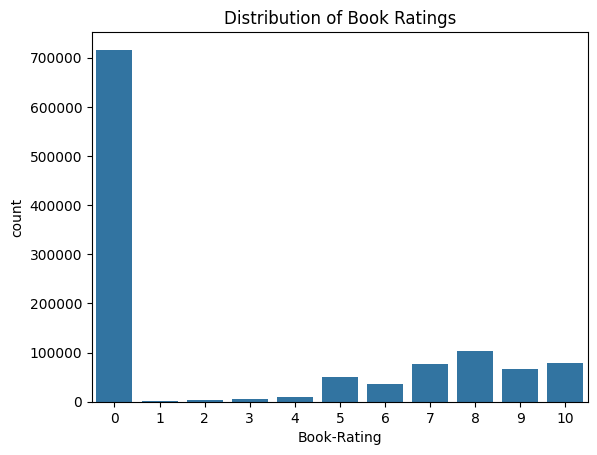

In [11]:
print("Rating Distribution:")
print(ratings["Book-Rating"].value_counts().sort_index())

print("\nNumber of Zero Ratings:")
print((ratings["Book-Rating"] == 0).sum())

sns.countplot(data=ratings, x="Book-Rating")
plt.title("Distribution of Book Ratings")
plt.show()

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Invalid ages below 5: 882
Invalid ages above 100: 366


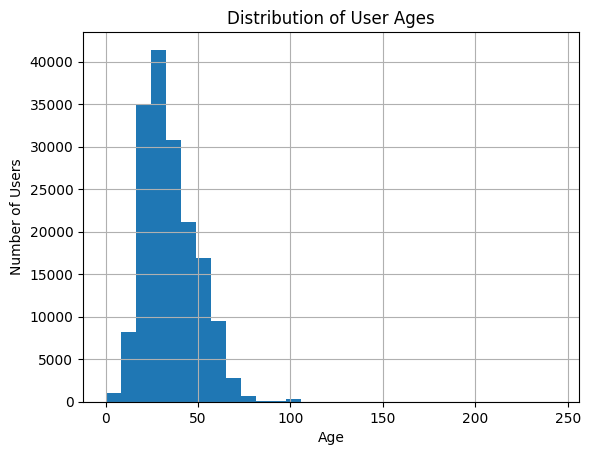

In [12]:
print(users["Age"].describe())

print("\nInvalid ages below 5:",
      (users["Age"] < 5).sum())

print("Invalid ages above 100:",
      (users["Age"] > 100).sum())

users["Age"].hist(bins=30)
plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()

count       271357.0
mean     1959.760817
std       257.994226
min              0.0
25%           1989.0
50%           1995.0
75%           2000.0
max           2050.0
Name: Year-Of-Publication, dtype: Float64

Zero publication years: 4618
Future publication years: 11


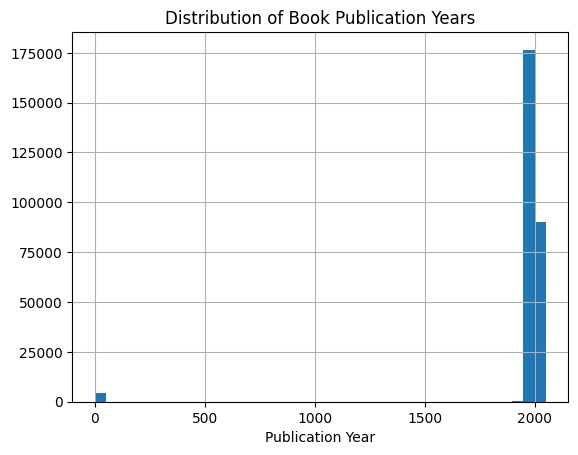

In [13]:
publication_years = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

print(publication_years.describe())

print("\nZero publication years:",
      (publication_years == 0).sum())

print("Future publication years:",
      (publication_years > datetime.now().year).sum())

publication_years.dropna().hist(bins=40)
plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.show()

In [14]:
ratings_per_user = ratings.groupby("User-ID").size()

ratings_per_book = ratings.groupby("ISBN").size()

print("Ratings per User:")
print(ratings_per_user.describe())

print("\nRatings per Book:")
print(ratings_per_book.describe())

Ratings per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


In [15]:
total_users = ratings["User-ID"].nunique()
total_books = ratings["ISBN"].nunique()

total_possible = total_users * total_books

actual_ratings = ratings[
    ["User-ID", "ISBN"]
].drop_duplicates().shape[0]

sparsity = (
    1 - actual_ratings / total_possible
) * 100

print("Total Users:", total_users)
print("Total Books:", total_books)
print("Possible User-Book Combinations:", total_possible)
print("Actual Rated Combinations:", actual_ratings)
print("Matrix Sparsity:", round(sparsity, 4), "%")

Total Users: 105283
Total Books: 340556
Possible User-Book Combinations: 35854757348
Actual Rated Combinations: 1149780
Matrix Sparsity: 99.9968 %


## Step 3: Data Cleaning and Silver Layer

In [16]:
users = pd.read_parquet("bronze/users.parquet")
books = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

# Work on copies
users = users.copy()
books = books.copy()
ratings = ratings.copy()

print("Bronze data loaded for cleaning!")

Bronze data loaded for cleaning!


In [17]:
users = users.drop_duplicates(subset=["User-ID"])

books = books.drop_duplicates(subset=["ISBN"])

ratings = ratings.drop_duplicates(
    subset=["User-ID", "ISBN"]
)

print("Duplicates removed!")

Duplicates removed!


In [18]:
ratings = ratings[
    ratings["Book-Rating"].between(1, 10)
]

print("Ratings after removing zeros:", len(ratings))

Ratings after removing zeros: 433671


In [19]:
users.loc[
    (users["Age"] < 5) | (users["Age"] > 100),
    "Age"
] = np.nan

median_age = users["Age"].median()

users["Age"] = users["Age"].fillna(median_age)

print("Median age used:", median_age)
print("Remaining missing ages:", users["Age"].isnull().sum())

Median age used: 32.0
Remaining missing ages: 0


In [20]:
users["Location"] = users["Location"].fillna("").str.strip()

location_parts = users["Location"].str.split(",", n=2, expand=True)

users["City"] = location_parts[0].str.strip()

users["State"] = location_parts[1].str.strip()

users["Country"] = location_parts[2].str.strip()

for col in ["City", "State", "Country"]:
    users[col] = users[col].replace("", pd.NA)
    users[col] = users[col].str.title()

users.drop(columns=["Location"], inplace=True)

print(users[["City", "State", "Country"]].head())

          City            State         Country
0          Nyc         New York             Usa
1     Stockton       California             Usa
2       Moscow  Yukon Territory          Russia
3        Porto         V.N.Gaia        Portugal
4  Farnborough            Hants  United Kingdom


In [21]:
books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"],
    errors="coerce"
)

current_year = datetime.now().year

books.loc[
    (books["Year-Of-Publication"] == 0) |
    (books["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

print("Invalid publication years handled!")

Invalid publication years handled!


In [22]:
# Striping extra spaces and standardize text
for col in ["Book-Title", "Book-Author", "Publisher"]:
    books[col] = books[col].astype("string").str.strip().str.title()

# Filling missing text values
books["Book-Author"] = books["Book-Author"].fillna("Unknown")
books["Publisher"] = books["Publisher"].fillna("Unknown")

# Cleaning ISBN
books["ISBN"] = books["ISBN"].astype("string").str.strip()
ratings["ISBN"] = ratings["ISBN"].astype("string").str.strip()

# Removing unnecessary image columns
books.drop(
    columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"],
    inplace=True
)

print("Text columns cleaned and image columns removed!")

Text columns cleaned and image columns removed!


In [23]:
ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"]) &
    ratings["ISBN"].isin(books["ISBN"])
]

print("Ratings after referential integrity check:", len(ratings))

Ratings after referential integrity check: 383843


In [24]:
min_ratings = 10

while True:

    previous_count = len(ratings)

    user_counts = ratings["User-ID"].value_counts()
    book_counts = ratings["ISBN"].value_counts()

    valid_users = user_counts[
        user_counts >= min_ratings
    ].index

    valid_books = book_counts[
        book_counts >= min_ratings
    ].index

    ratings = ratings[
        ratings["User-ID"].isin(valid_users) &
        ratings["ISBN"].isin(valid_books)
    ]

    if len(ratings) == previous_count:
        break

# Retain only users and books present in final ratings
users = users[
    users["User-ID"].isin(ratings["User-ID"])
]

books = books[
    books["ISBN"].isin(ratings["ISBN"])
]

print("Filtering completed!")
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Filtering completed!
Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)


In [25]:
users.to_parquet("silver/users.parquet", index=False)

books.to_parquet("silver/books.parquet", index=False)

ratings.to_parquet("silver/ratings.parquet", index=False)

print("Silver layer created successfully!")

Silver layer created successfully!


In [26]:
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Users: (1820, 6)
Books: (2030, 6)
Ratings: (41456, 4)


In [27]:
print("Missing ages:", users["Age"].isnull().sum())

print("Zero ratings:",
      (ratings["Book-Rating"] == 0).sum())

print("Minimum ratings per user:",
      ratings.groupby("User-ID").size().min())

print("Minimum ratings per book:",
      ratings.groupby("ISBN").size().min())

Missing ages: 0
Zero ratings: 0
Minimum ratings per user: 10
Minimum ratings per book: 10


## Step 4: Gold Layer – Model Ready Data

In [28]:
users = pd.read_parquet("silver/users.parquet")
books = pd.read_parquet("silver/books.parquet")
ratings = pd.read_parquet("silver/ratings.parquet")

print("Silver data loaded successfully!")

Silver data loaded successfully!


In [29]:
from scipy.sparse import csr_matrix, save_npz, load_npz
import json

# Creating unique user and book lists
user_ids = ratings["User-ID"].unique()
book_ids = ratings["ISBN"].unique()

# Creating index mappings
user_to_idx = {
    user: idx for idx, user in enumerate(user_ids)
}

book_to_idx = {
    book: idx for idx, book in enumerate(book_ids)
}

# Mapping original IDs to matrix indices
row = ratings["User-ID"].map(user_to_idx)
col = ratings["ISBN"].map(book_to_idx)

data = ratings["Book-Rating"].values

# Creating sparse matrix
rating_matrix = csr_matrix(
    (data, (row, col)),
    shape=(len(user_ids), len(book_ids))
)

print("Matrix Shape:", rating_matrix.shape)
print("Number of stored ratings:", rating_matrix.nnz)

Matrix Shape: (1820, 2030)
Number of stored ratings: 41456


In [30]:
save_npz("gold/rating_matrix.npz", rating_matrix)

print("Rating matrix saved!")

Rating matrix saved!


In [31]:
with open("gold/user_to_idx.json", "w") as f:
    json.dump(
        {str(k): int(v) for k, v in user_to_idx.items()},
        f
    )

with open("gold/book_to_idx.json", "w") as f:
    json.dump(book_to_idx, f)

print("Mappings saved!")

Mappings saved!


In [32]:
book_lookup = books[
    ["ISBN", "Book-Title", "Book-Author"]
].copy()

book_lookup.to_parquet(
    "gold/book_lookup.parquet",
    index=False
)

print(book_lookup.head())

         ISBN                            Book-Title       Book-Author
0  0440234743                         The Testament      John Grisham
1  0452264464  Beloved (Plume Contemporary Fiction)     Toni Morrison
2  0971880107                           Wild Animus      Rich Shapero
3  0345402871                              Airframe  Michael Crichton
4  0345417623                              Timeline  Michael Crichton


In [33]:
user_aggregates = ratings.groupby("User-ID").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

user_aggregates.to_parquet(
    "gold/user_aggregates.parquet",
    index=False
)

print(user_aggregates.head())

   User-ID  average_rating  number_of_ratings
0      243        7.769231                 13
1      254        8.450000                 20
2      638        9.454545                 22
3      805        8.400000                 10
4      882        8.235294                 17


In [34]:
book_aggregates = ratings.groupby("ISBN").agg(
    average_rating=("Book-Rating", "mean"),
    number_of_ratings=("Book-Rating", "count")
).reset_index()

book_aggregates.to_parquet(
    "gold/book_aggregates.parquet",
    index=False
)

print(book_aggregates.head())

         ISBN  average_rating  number_of_ratings
0  0020199600        8.166667                 12
1  0020442203        8.833333                 12
2  002542730X        7.481481                 27
3  0028604199        7.900000                 10
4  0060002050        7.545455                 11


In [35]:
print("Rating Matrix:", rating_matrix.shape)

print("\nBook Lookup:", book_lookup.shape)

print("\nUser Aggregates:", user_aggregates.shape)

print("\nBook Aggregates:", book_aggregates.shape)

print("\nGold files:")
print(os.listdir("gold"))

Rating Matrix: (1820, 2030)

Book Lookup: (2030, 3)

User Aggregates: (1820, 3)

Book Aggregates: (2030, 3)

Gold files:
['user_to_idx.json', 'book_aggregates.parquet', 'rating_matrix.npz', 'user_aggregates.parquet', 'book_lookup.parquet', 'book_to_idx.json']


## Step 5: Item-Based Collaborative Filtering

In [36]:
from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors
import json

# Loading sparse rating matrix
rating_matrix = load_npz("gold/rating_matrix.npz")

# Loading mappings
with open("gold/user_to_idx.json", "r") as f:
    user_to_idx = json.load(f)

with open("gold/book_to_idx.json", "r") as f:
    book_to_idx = json.load(f)

# Converting user IDs back to integers
user_to_idx = {
    int(k): v for k, v in user_to_idx.items()
}

# Load book lookup
book_lookup = pd.read_parquet("gold/book_lookup.parquet")

# Maintain the exact order used when creating the matrix
user_ids = list(user_to_idx.keys())

book_ids = [
    isbn for isbn, idx in
    sorted(book_to_idx.items(), key=lambda x: x[1])
]

print("Rating matrix loaded:", rating_matrix.shape)

Rating matrix loaded: (1820, 2030)


In [37]:
book_user_matrix = rating_matrix.T.tocsr()

print("Book-user matrix shape:", book_user_matrix.shape)

Book-user matrix shape: (2030, 1820)


In [38]:
model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=11,
    n_jobs=-1
)

model.fit(book_user_matrix)

print("Cosine similarity model trained successfully!")

Cosine similarity model trained successfully!


In [39]:
# Create a fast lookup using ISBN
book_info = book_lookup.set_index("ISBN")

def get_similar_books(book_title, n=10):

    # Find matching book title
    matches = book_info[
        book_info["Book-Title"].str.casefold() == book_title.casefold()
    ]

    if matches.empty:
        return "Book not found!"

    isbn = matches.index[0]
    book_idx = book_to_idx[str(isbn)]

    # Find similar books
    distances, indices = model.kneighbors(
        book_user_matrix[book_idx],
        n_neighbors=min(50, len(book_ids))
    )

    results = []
    seen_titles = {book_title.casefold()}

    for distance, idx in zip(distances[0], indices[0]):

        similar_isbn = book_ids[idx]
        title = book_info.loc[similar_isbn, "Book-Title"]
        author = book_info.loc[similar_isbn, "Book-Author"]

        if title.casefold() in seen_titles:
            continue

        seen_titles.add(title.casefold())

        results.append({
            "Book": title,
            "Author": author,
            "Similarity": round(1 - distance, 4)
        })

        if len(results) == n:
            break

    return pd.DataFrame(results)

In [40]:
print(get_similar_books(book_lookup.iloc[0]["Book-Title"]))

                                                Book  \
0  Monster : A Novel (Alex Delaware Novels (Paper...   
1                                   The Runaway Jury   
2  The Bone Collector (Lincoln Rhyme Novels (Pape...   
3                                   Call Of The Wild   
4                                   The Simple Truth   
5                                  The Street Lawyer   
6                                     Atlantis Found   
7                                           Outbreak   
8                                From Potter'S Field   
9                                  Writ Of Execution   

                      Author  Similarity  
0         Jonathan Kellerman      0.2528  
1               John Grisham      0.2378  
2                Jeff Deaver      0.2376  
3                Jack London      0.2359  
4             David Baldacci      0.2356  
5               John Grisham      0.2198  
6              Clive Cussler      0.1994  
7                 Robin Cook      0.198

In [41]:
def recommend(user_id, n=10):

    if user_id not in user_to_idx:
        return "User not found!"

    # Getting the user's rating vector
    user_idx = user_to_idx[user_id]

    user_ratings = rating_matrix[user_idx].toarray().flatten()

    # Finding books already rated by the user
    read_books = set(np.where(user_ratings > 0)[0])

    # Finding books rated 7 or higher
    liked_books = np.where(user_ratings >= 7)[0]

    if len(liked_books) == 0:
        return "No highly rated books found for this user!"

    scores = {}

    # Finding similar books for each liked book
    for book_idx in liked_books:

        user_rating = user_ratings[book_idx]

        distances, indices = model.kneighbors(
            book_user_matrix[book_idx],
            n_neighbors=min(11, len(book_ids))
        )

        for distance, similar_idx in zip(
            distances[0], indices[0]
        ):

            # Skip books already rated
            if similar_idx in read_books:
                continue

            similarity = 1 - distance

            # Weight similarity by user's rating
            weighted_score = similarity * user_rating

            scores[similar_idx] = (
                scores.get(similar_idx, 0) + weighted_score
            )

    # Rank books by recommendation score
    ranked_books = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )[:n]

    recommendations = []

    for idx, score in ranked_books:

        isbn = book_ids[idx]

        recommendations.append({
    "ISBN": isbn,
    "Book": book_info.loc[isbn, "Book-Title"],
    "Author": book_info.loc[isbn, "Book-Author"],
    "Recommendation Score": round(score, 4)
})

    return pd.DataFrame(recommendations)

In [42]:
def show_user_demo(user_id):

    print("\n" + "="*60)
    print("USER ID:", user_id)
    print("="*60)

    user_idx = user_to_idx[user_id]

    user_ratings = rating_matrix[user_idx].toarray().flatten()

    # Find books rated 7 or higher
    liked_indices = np.where(user_ratings >= 7)[0]

    # Sort by highest rating
    liked_indices = sorted(
        liked_indices,
        key=lambda idx: user_ratings[idx],
        reverse=True
    )

    print("\nBOOKS LIKED BY USER:")

    for idx in liked_indices[:10]:

        isbn = book_ids[idx]

        print(
            book_info.loc[isbn, "Book-Title"],
            "| Rating:",
            int(user_ratings[idx])
        )

    print("\nRECOMMENDED BOOKS:")

    print(recommend(user_id, n=10))

In [43]:
liked_counts = {}

for user_id, idx in user_to_idx.items():

    user_ratings = rating_matrix[idx].toarray().flatten()

    liked_counts[user_id] = np.sum(user_ratings >= 7)

demo_users = sorted(
    liked_counts,
    key=liked_counts.get,
    reverse=True
)[:3]

print("Selected demo users:", demo_users)

Selected demo users: [11676, 16795, 104636]


In [44]:
for uid in demo_users:
    show_user_demo(uid)


USER ID: 11676

BOOKS LIKED BY USER:
The Return Of The Indian (Indian In The Cupboard) | Rating: 10
C Is For Corpse (Kinsey Millhone Mysteries (Paperback)) | Rating: 10
Trading Places | Rating: 10
The Venetian'S Wife: A Strangely Sensual Tale Of A Renaissance Explorer, A Computer, And A Metamorphosis | Rating: 10
Hemlock Bay | Rating: 10
Before I Say Good-Bye : A Novel | Rating: 10
Chicken Soup For The Woman'S Soul (Chicken Soup For The Soul Series (Paper)) | Rating: 10
The Playboy | Rating: 10
Key Of Valor (Roberts, Nora. Key Trilogy, 3.) | Rating: 10
Courting Trouble | Rating: 10

RECOMMENDED BOOKS:
         ISBN                                               Book  \
0  0440167531                                           Palomino   
1  0373270976              Night Shield (Intimate Moments, 1027)   
2  0842332251  The Mark: The Beast Rules The World (Left Behi...   
3  0842329285  The Indwelling: The Beast Takes Possession (Le...   
4  0670839531         Needful Things: The Last Cas

In [45]:
for uid in demo_users:

    user_idx = user_to_idx[uid]

    # Books already rated by the user
    read_indices = set(
        np.where(rating_matrix[user_idx].toarray().flatten() > 0)[0]
    )

    # Generate recommendations
    result = recommend(uid, n=10)

    # Convert recommended ISBNs into matrix indices
    recommended_indices = {
        book_to_idx[str(isbn)] for isbn in result["ISBN"]
    }

    print("\nUser:", uid)
    print("Recommendations generated:", len(result))
    print("All recommendations are unseen:", recommended_indices.isdisjoint(read_indices))


User: 11676
Recommendations generated: 10
All recommendations are unseen: True

User: 16795
Recommendations generated: 10
All recommendations are unseen: True

User: 104636
Recommendations generated: 10
All recommendations are unseen: True


In [46]:
# Search for Harry Potter books in our dataset

book_lookup[
    book_lookup["Book-Title"].str.contains(
        "Harry Potter", case=False, na=False
    )
]["Book-Title"].drop_duplicates().head(20).tolist()

["Harry Potter And The Sorcerer'S Stone (Harry Potter (Paperback))",
 "Harry Potter And The Sorcerer'S Stone (Book 1)",
 'Harry Potter And The Chamber Of Secrets (Book 2)',
 'Harry Potter And The Prisoner Of Azkaban (Book 3)',
 'Harry Potter And The Goblet Of Fire (Book 4)',
 'Harry Potter And The Order Of The Phoenix (Book 5)',
 'Harry Potter And The Chamber Of Secrets Postcard Book']

In [47]:
test_title = "Harry Potter And The Sorcerer'S Stone (Harry Potter (Paperback))"

similar_books = get_similar_books(test_title, n=10)

print("Input Book:", test_title)
print("\n10 Most Similar Books:")
display(similar_books)

Input Book: Harry Potter And The Sorcerer'S Stone (Harry Potter (Paperback))

10 Most Similar Books:


,Book,Author,Similarity
0,Harry Potter And The Chamber Of Secrets (Book 2),J. K. Rowling,0.4110
1,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,0.3156
2,Harry Potter And The Goblet Of Fire (Book 4),J. K. Rowling,0.2541
3,Harry Potter And The Order Of The Phoenix (Boo...,J. K. Rowling,0.2443
4,Fried Green Tomatoes At The Whistle Stop Cafe,Fannie Flagg,0.1885
5,Love Story,Erich Segal,0.1696
6,Anne Of Green Gables (Anne Of Green Gables Nov...,L.M. Montgomery,0.1633
7,Anne Of Ingleside (Anne Of Green Gables Novels...,L.M. Montgomery,0.1561
8,Like Water For Chocolate: A Novel In Monthly I...,Laura Esquivel,0.1551
9,"Blood Of The Fold (Sword Of Truth, Book 3)",Terry Goodkind,0.1542


## 7. Conclusion

In this project, we developed a Book Recommendation System using the Book-Crossing dataset and the Medallion Architecture.

The project was divided into three layers:

- **Bronze Layer:** Raw datasets were ingested, timestamped, and stored in Parquet format.
- **Silver Layer:** Data cleaning, preprocessing, deduplication, handling missing values, and filtering were performed.
- **Gold Layer:** A sparse user-book rating matrix, book lookup table, and user/book aggregates were created.

### Recommendation Approach

We implemented Item-Based Collaborative Filtering using cosine similarity and the Nearest Neighbors algorithm.

Two recommendation functions were developed:

1. `get_similar_books(title, n)` – Finds books similar to a given book based on user rating patterns.
2. `recommend(user_id, n)` – Recommends books based on a user's highly rated books while excluding books they have already rated.

### Validation

The recommendation system was tested using three sample users. Each generated 10 recommendations, and all recommendations were verified to be previously unrated by the respective users.

The book similarity function was also tested and successfully returned 10 distinct similar book titles.

### Final Outcome

The project demonstrates how raw data can be transformed through a structured data pipeline into a recommendation system using collaborative filtering and sparse matrix operations.